# Interpretable model V1: forest vs plantation

Predict `label_forest` (1 = natural forest, 0 = plantation) from `master_features_v3_slim.csv`, with four simple models: CART, an optimal classification tree (Interpretable AI, run through Julia), and logistic regression with lasso and with ridge.

- **Split** (from the CSV): train on `dev`, choose settings on `lockbox` (validation), score once on `heldback` (test).
- **AUC** = chance that a random forest point gets a higher forest score than a random plantation (0.5 = coin flip, 1 = perfect).
- **Plantations caught** = share of plantations called plantation at a cutoff that hides only 5% of forest (that is, calls 5% of real forest "plantation"). The cutoff is set on `lockbox` and applied unchanged to `heldback`.

In [1]:
import pandas as pd, numpy as np, statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

In [2]:
df = pd.read_csv('../Master Data/master_features_v3_slim.csv').dropna(subset=['nc_F_VH_median'])  # 1 dev row has no radar data
# |Spearman| >= 0.8 on dev: drop the weaker feature of each pair
correlation_drop = ['mm_B6_win', 'nc_B_SWIR_phase_sin', 'lh_ever_open', 'lh_n_changes', 'nc_A_SAG', 'nc_su3_NDMI']
mb_drop = ['lh_natural_run_years'] # because it comes from MapBiomas
benchmark_drop = ['nc_A_SAG', 'nc_chm_mean_r15', 'nc_chm_stdDev_r15'] # 
drop = correlation_drop + mb_drop + benchmark_drop
X_cols = [c for c in df.columns[7:] if c not in drop]
y = 'label_forest'
train, val, test = (df[df.split == s] for s in ['dev', 'lockbox', 'heldback'])
print(len(X_cols), 'features |', {s: len(d) for s, d in zip(['train', 'val', 'test'], [train, val, test])})

25 features | {'train': 2023, 'val': 436, 'test': 207}


In [3]:
def evaluate(name, p_val, p_test):
    """p_* = predicted probability of forest. Cutoff hides 5% of lockbox forest."""
    cut = np.quantile(p_val[val[y] == 1], 0.05)
    row = {'model': name}
    for s, d, p in [('val', val, p_val), ('test', test, p_test)]:
        row[f'AUC {s}'] = roc_auc_score(d[y], p)
        row[f'plantations caught {s}'] = (p[d[y] == 0] < cut).mean()
        row[f'forest hidden {s}'] = (p[d[y] == 1] < cut).mean()
    return row

def tune(make, grid):
    """Fit one model per setting on train, keep the best lockbox AUC."""
    fits = [make(g).fit(train[X_cols], train[y]) for g in grid]
    aucs = [roc_auc_score(val[y], m.predict_proba(val[X_cols])[:, 1]) for m in fits]
    return fits[int(np.argmax(aucs))], grid[int(np.argmax(aucs))]

results = []

## 0. Dropping highest correlated features

Two features that move together carry nearly the same information. Keeping both makes regression coefficients unstable and lets a tree pick between them almost at random. We measure this with the **Spearman correlation** (from −1 to +1): +1 = the two features rank the points in exactly the same order, −1 = in exactly the opposite order, 0 = no relation. It is computed on the training (`dev`) points only, over all 34 candidate features.

Features are ordered so that correlated ones sit next to each other. Numbers are shown only where |correlation| ≥ 0.8, the threshold used for the `drop` list above. Grey labels are the features that were dropped.

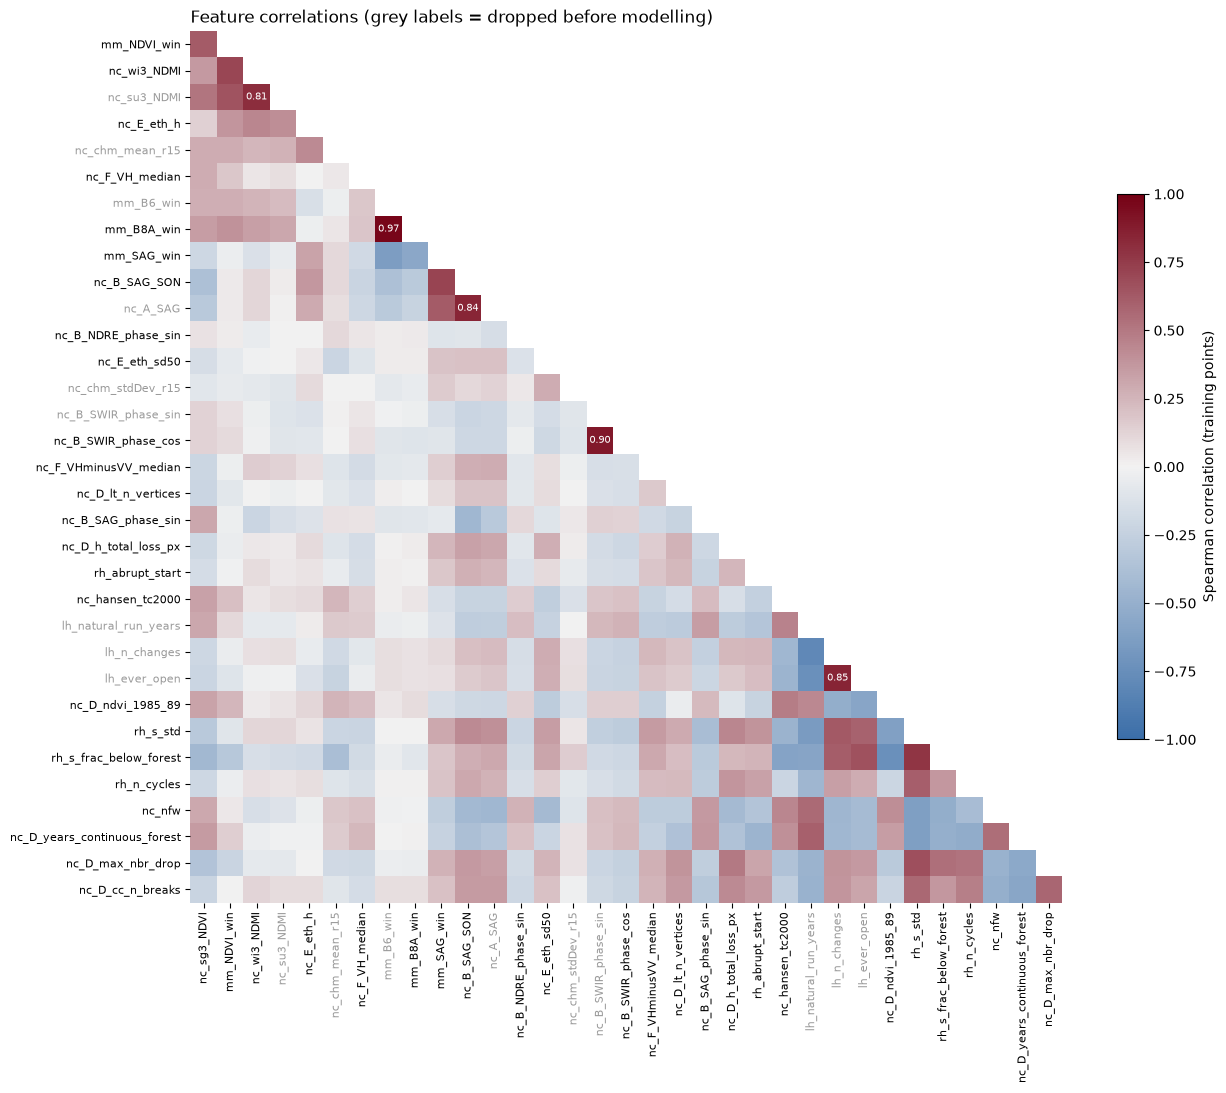

,feature A,feature B,Spearman,dropped
0,mm_B6_win,mm_B8A_win,0.971,mm_B6_win
1,nc_B_SWIR_phase_sin,nc_B_SWIR_phase_cos,0.898,nc_B_SWIR_phase_sin
2,lh_n_changes,lh_ever_open,0.846,"lh_n_changes, lh_ever_open"
3,nc_B_SAG_SON,nc_A_SAG,0.838,nc_A_SAG
4,nc_wi3_NDMI,nc_su3_NDMI,0.811,nc_su3_NDMI
5,lh_natural_run_years,lh_n_changes,-0.794,"lh_natural_run_years, lh_n_changes"
6,rh_s_std,rh_s_frac_below_forest,0.778,—
7,lh_natural_run_years,lh_ever_open,-0.736,"lh_natural_run_years, lh_ever_open"
8,nc_D_ndvi_1985_89,rh_s_frac_below_forest,-0.736,—
9,nc_B_SAG_SON,mm_SAG_win,0.712,—


In [ ]:
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
from matplotlib.colors import LinearSegmentedColormap

all_cols = list(df.columns[7:])                 # all 34 candidate features, before the drop above
rho = train[all_cols].corr(method='spearman')   # training (dev) points only
order = leaves_list(linkage(squareform(1 - rho.abs(), checks=False), 'average'))  # correlated features side by side
rho = rho.iloc[order, order]
low = rho.iloc[1:, :-1]                          # lower triangle without the diagonal

# Blue = negative, grey = none, burgundy = positive. Numbers shown where |rho| >= 0.8.
cmap = LinearSegmentedColormap.from_list('div', ['#3B6EA8', '#F2F2F2', '#750014'])
fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(low.where(np.tril(np.ones(low.shape, bool))), cmap=cmap, vmin=-1, vmax=1)
for i in range(len(low)):
    for j in range(i + 1):
        if abs(low.iat[i, j]) >= 0.8:
            ax.text(j, i, f'{low.iat[i, j]:.2f}', ha='center', va='center', fontsize=7, color='white')
ax.set_xticks(range(low.shape[1]), low.columns, rotation=90, fontsize=8)
ax.set_yticks(range(low.shape[0]), low.index, fontsize=8)
for lbl in ax.get_xticklabels() + ax.get_yticklabels():  # features dropped above in grey
    if lbl.get_text() in drop:
        lbl.set_color('#9A9A9A')
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.6, label='Spearman correlation (training points)')
ax.set_title('Feature correlations (grey labels = dropped before modelling)', loc='left')
fig.tight_layout()
plt.show()

# The 12 most correlated pairs, and which of the two features was dropped
iu = np.triu_indices(len(all_cols), 1)
C = train[all_cols].corr(method='spearman')
pairs = pd.DataFrame({'feature A': C.index[iu[0]], 'feature B': C.columns[iu[1]], 'Spearman': C.values[iu]})
pairs = pairs.reindex(pairs.Spearman.abs().sort_values(ascending=False).index).head(12).reset_index(drop=True)
pairs['dropped'] = [', '.join(f for f in (a, b) if f in drop) or '—' for a, b in zip(pairs['feature A'], pairs['feature B'])]
pairs.round(3)

## 1. CART (classic decision tree; depth 1–5 chosen on lockbox, capped at 5 so it stays readable)

In [5]:
cart, depth = tune(lambda d: DecisionTreeClassifier(max_depth=d, min_samples_leaf=20, random_state=0), list(range(1, 6)))
results.append(evaluate(f'CART (depth {depth})', cart.predict_proba(val[X_cols])[:, 1], cart.predict_proba(test[X_cols])[:, 1]))


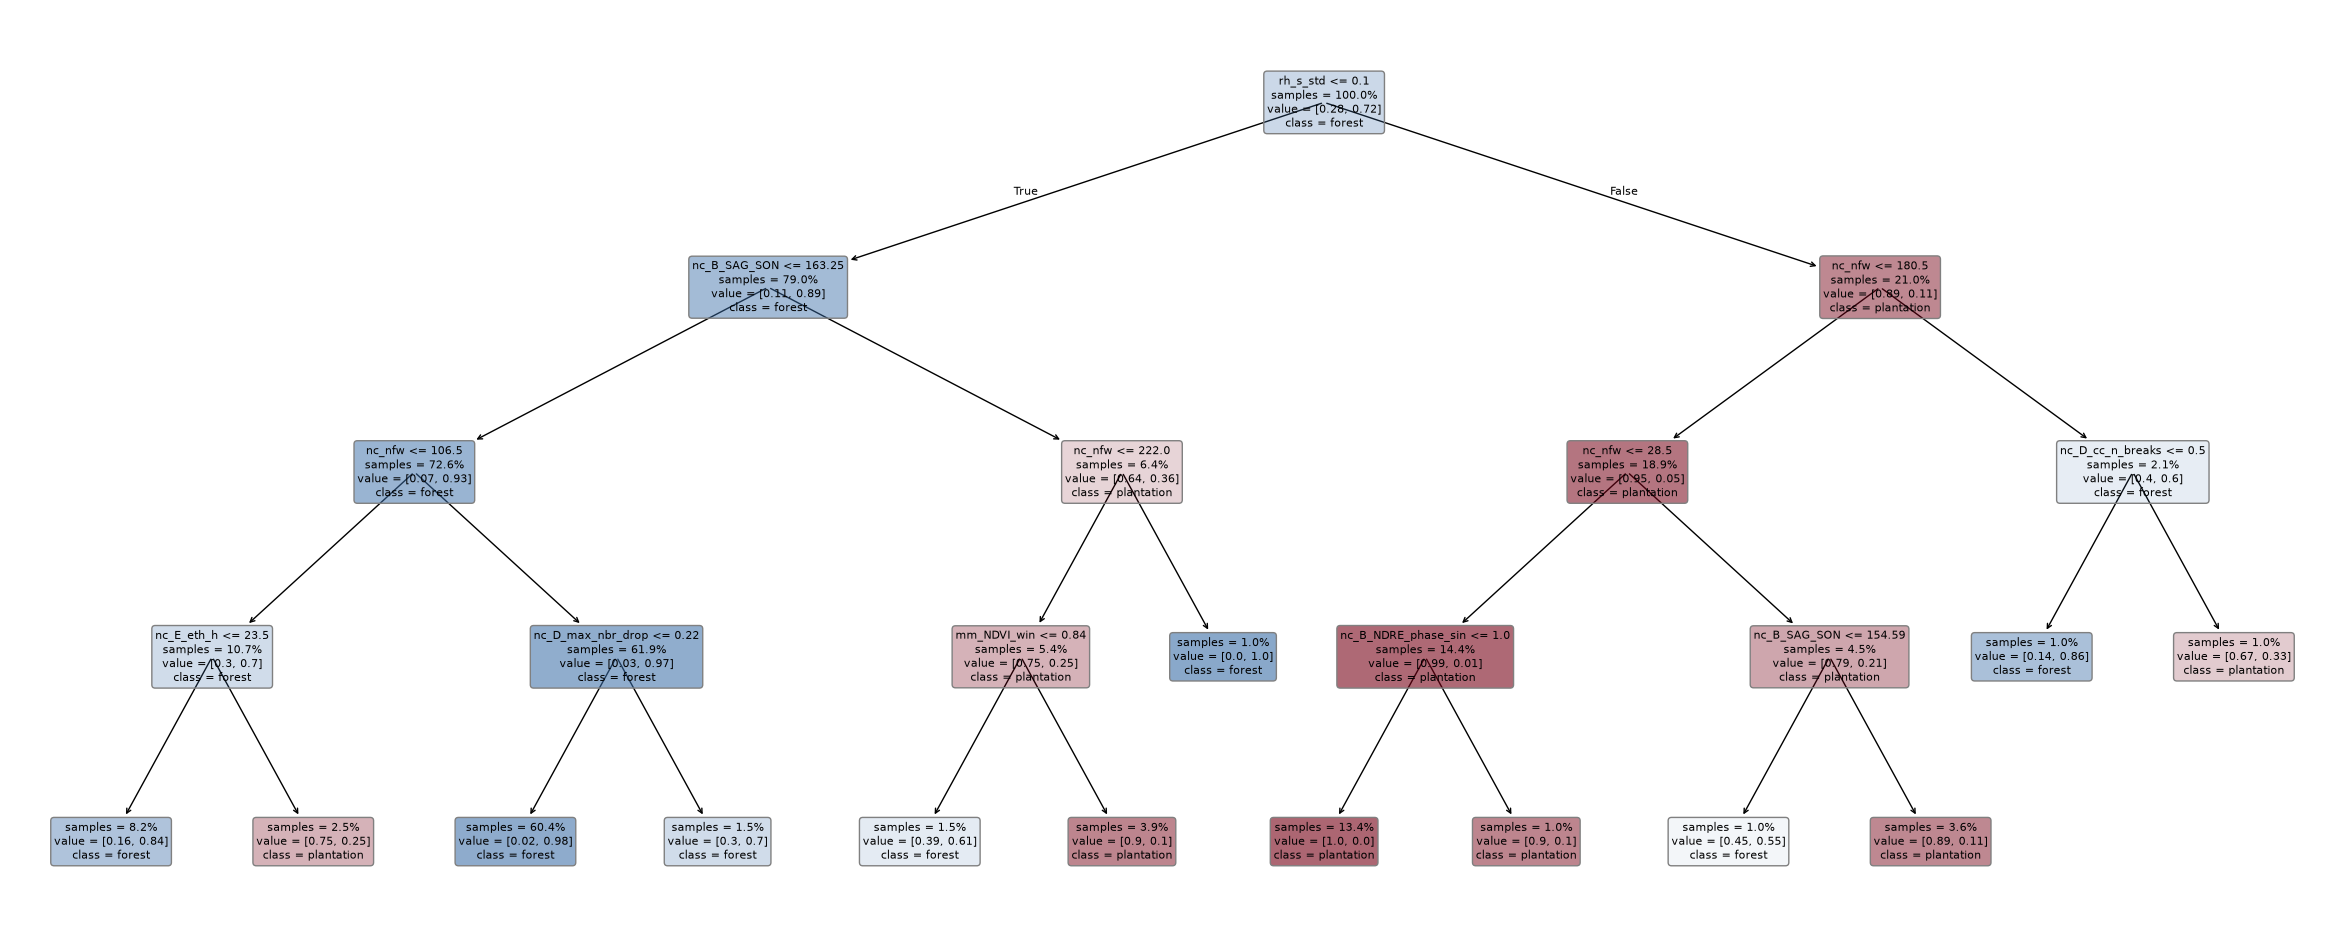

In [6]:
# Blue = forest, burgundy = plantation; darker = purer node. Each box: split rule, share of training points, class mix.
fig, ax = plt.subplots(figsize=(30, 12))
nodes = plot_tree(cart, feature_names=X_cols, class_names=['plantation', 'forest'], impurity=False, proportion=True, rounded=True, precision=2, fontsize=8, ax=ax)
for box in nodes:  # colour each node from its printed class mix [plantation, forest]
    if 'value' in box.get_text():
        f = float(box.get_text().split('value = [')[1].split(']')[0].split(',')[1])
        box.set_bbox(dict(boxstyle='round', ec='grey', fc=to_rgba('#3B6EA8' if f >= 0.5 else '#750014', 1.2 * abs(f - 0.5))))
plt.show()

## 2. Optimal classification tree (Interpretable AI, run through Julia)

CART grows a tree greedily, one split at a time. An **optimal tree** instead searches for the best tree of a given depth as a whole. We use **Interpretable AI's Optimal Trees** (the MIT method). Its Python package won't run on this laptop, but its Julia version does. So the notebook writes the three splits to a temporary folder outside the repo, runs `helper_train_iai.jl` with the IAI build of Julia (`julia +1.11.6/IAI/3.2.2`), and reads the predictions back.

- **All 28 features, on their original values.**
- **Depth 1–5, chosen on lockbox,** the same range as CART. For each depth, IAI tunes its own complexity penalty (`cp`, which prunes splits that don't help) on an internal split of the training data only. The leaf minimum is 20 points, as for CART.

A tree only predicts a class, so for AUC each point gets its leaf's **share of forest among training points**, the same score CART uses. The tree is drawn in the same format as CART's. Note that IAI splits on "feature < threshold" where CART uses "≤". Takes about 1–3 minutes, including up to a minute for Julia to start.

In [7]:
RUN_IAI = True  # set False to skip (needs juliaup with the IAI channel; about 1.5–3 min)
IAI_JULIA = ['julia', '+1.11.6/IAI/3.2.2']  # juliaup channel with IAI preloaded (plain `julia` has no IAI)
import os, subprocess, tempfile

try:
    assert RUN_IAI, 'RUN_IAI is False'
    iai_dir = tempfile.mkdtemp(prefix='iai_')  # outside the repo: these CSVs hold one row per point
    for name, d in [('train', train), ('val', val), ('test', test)]:
        d[X_cols].assign(y=d[y]).to_csv(os.path.join(iai_dir, f'{name}.csv'), index=False)
    run = subprocess.run(IAI_JULIA + [os.path.abspath('helper_train_iai.jl'), iai_dir, '5', '20'],
                         capture_output=True, text=True, encoding='utf-8', errors='replace')
    assert run.returncode == 0, run.stderr[-1500:]
    print(run.stdout)
    iai_p = {s: pd.read_csv(os.path.join(iai_dir, f'p_{s}.csv')) for s in ['val', 'test']}  # P(forest), one column per depth
    iai_auc = {int(c.split('_')[1]): roc_auc_score(val[y], iai_p['val'][c]) for c in iai_p['val']}
    print('Lockbox AUC by depth:', {d: round(a, 3) for d, a in iai_auc.items()})
    iai_depth = max(iai_auc, key=iai_auc.get)  # best lockbox AUC, as for the other models
    print(f'Chosen on lockbox: depth {iai_depth} (tree drawn below)')
    results.append(evaluate(f'Optimal tree, IAI (depth {iai_depth})',
                            iai_p['val'][f'depth_{iai_depth}'].to_numpy(), iai_p['test'][f'depth_{iai_depth}'].to_numpy()))
except Exception as e:
    iai_depth = None
    print('IAI optimal tree skipped:', type(e).__name__, str(e)[:1500])

depth 1: 3 nodes, 8.7 s
depth 2: 5 nodes, 1.5 s
depth 3: 15 nodes, 3.9 s
depth 4: 27 nodes, 7.9 s
depth 5: 31 nodes, 8.4 s

Lockbox AUC by depth: {1: 0.858, 2: 0.872, 3: 0.954, 4: 0.957, 5: 0.979}
Chosen on lockbox: depth 5 (tree drawn below)


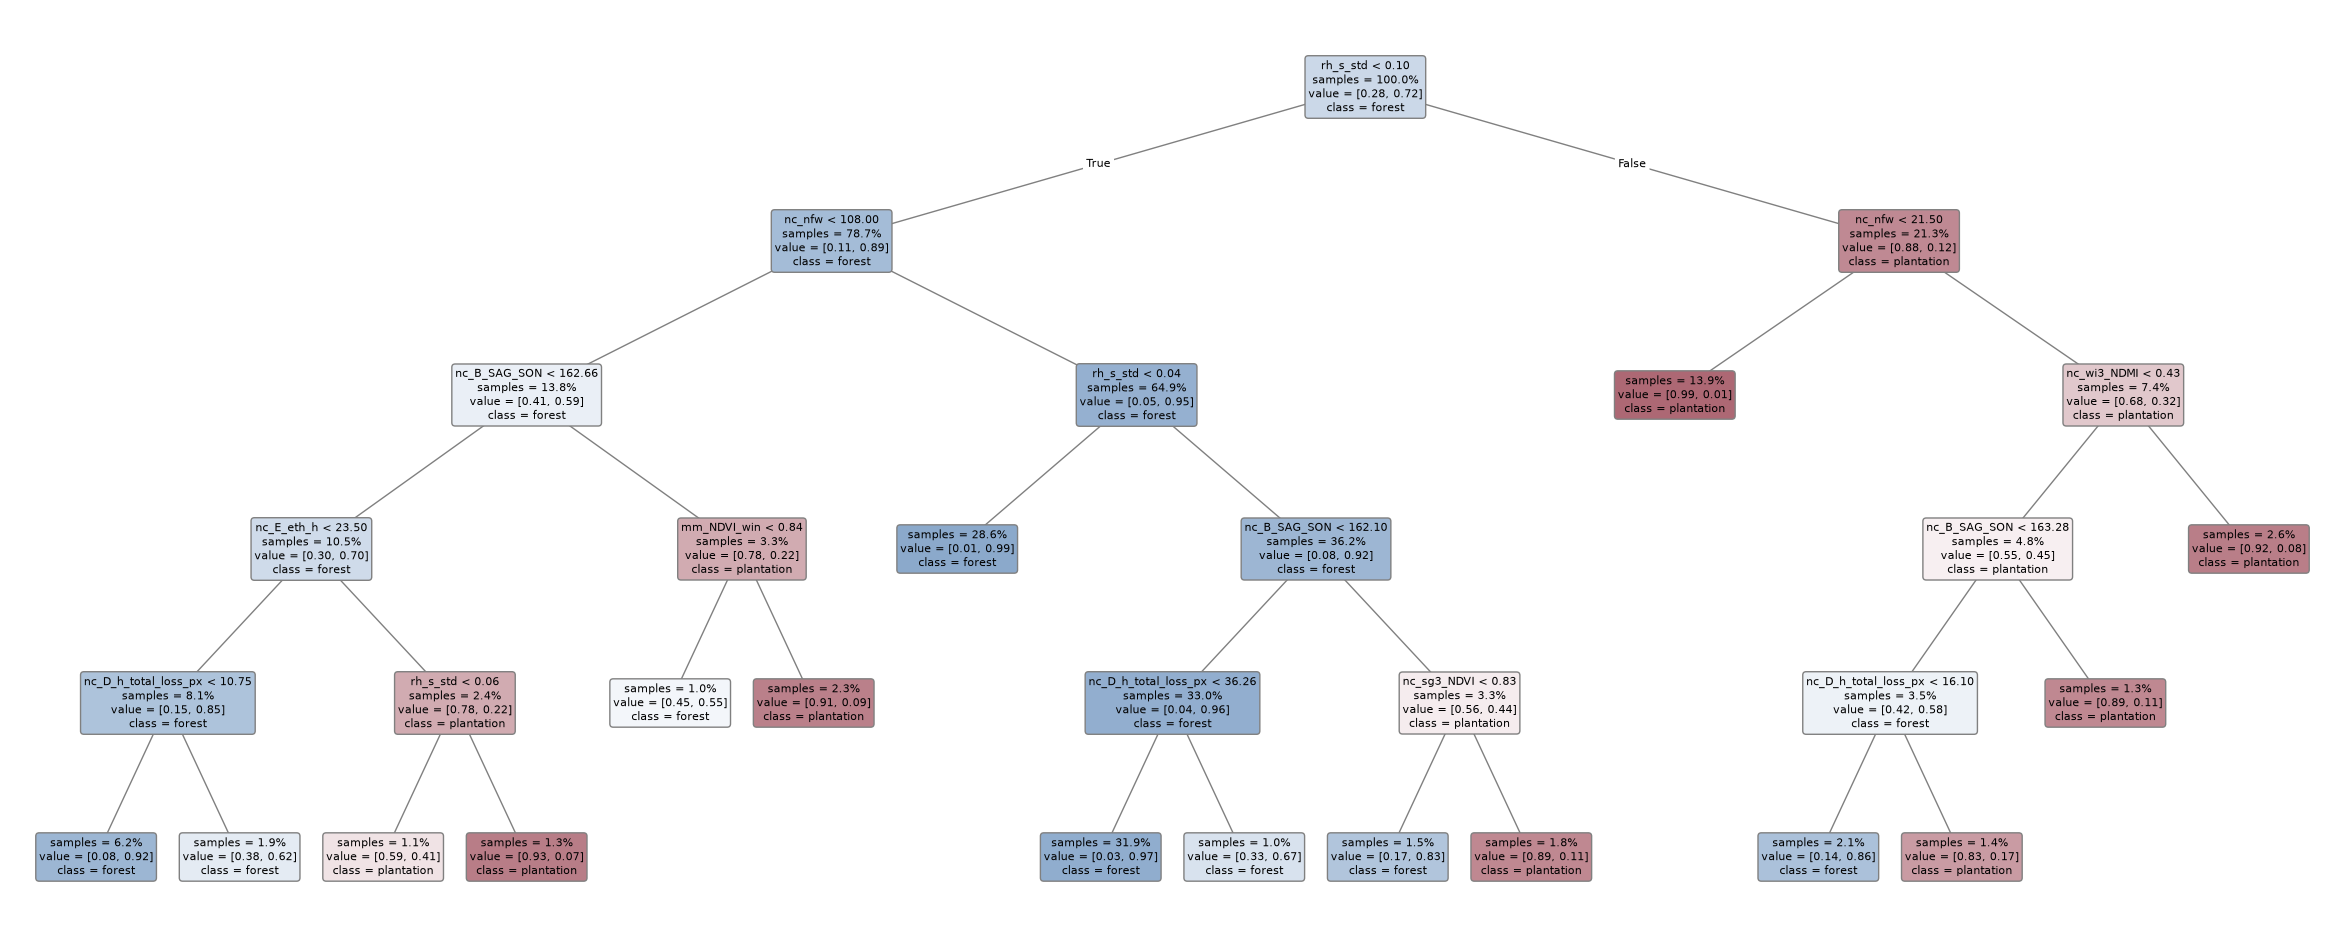

In [8]:
# Same format as the CART picture: blue = forest, burgundy = plantation; darker = purer node.
# Each box: split rule (points with feature < threshold go left, "True"), share of training points, class mix.
def plot_iai_tree(nodes, ax, fontsize=8):
    nodes = nodes.set_index('node')
    pos, n_leaves = {}, [0]
    def place(n):  # leaves left to right, each parent centred over its two children
        r = nodes.loc[n]
        if r.is_leaf:
            pos[n] = n_leaves[0]; n_leaves[0] += 1
        else:
            place(r.lower); place(r.upper); pos[n] = (pos[r.lower] + pos[r.upper]) / 2
    place(1)
    xy = {n: (pos[n], -nodes.loc[n, 'depth']) for n in nodes.index}
    for n, r in nodes[~nodes.is_leaf].iterrows():  # edges, drawn under the boxes
        for child, word in [(r.lower, 'True'), (r.upper, 'False')]:
            ax.plot(*zip(xy[n], xy[child]), color='grey', lw=1, zorder=1)
            if n == 1:
                ax.text(*np.mean([xy[n], xy[child]], axis=0), word, ha='center', va='center', fontsize=fontsize,
                        bbox=dict(boxstyle='round', fc='white', ec='none'), zorder=2)
    n_total = nodes.loc[1, 'n_train']
    for n, r in nodes.iterrows():
        f = r.p_forest
        a = min(1.2 * abs(f - 0.5), 1)
        fill = tuple(a * np.array(to_rgba('#3B6EA8' if f >= 0.5 else '#750014')[:3]) + (1 - a))  # opaque, same shade as CART
        text = ('' if r.is_leaf else f'{r.feature} < {r.threshold:.2f}\n') + \
               f'samples = {100 * r.n_train / n_total:.1f}%\nvalue = [{1 - f:.2f}, {f:.2f}]\nclass = {"forest" if f >= 0.5 else "plantation"}'
        ax.text(*xy[n], text, ha='center', va='center', fontsize=fontsize, zorder=3,
                bbox=dict(boxstyle='round', ec='grey', fc=fill))
    ax.set_xlim(-0.6, n_leaves[0] - 0.4); ax.set_ylim(-nodes.depth.max() - 0.5, 0.5); ax.axis('off')

if iai_depth is not None:
    iai_nodes = pd.read_csv(os.path.join(iai_dir, f'tree_depth_{iai_depth}_nodes.csv'), keep_default_na=False, na_values=['NaN'])
    fig, ax = plt.subplots(figsize=(30, 12))
    plot_iai_tree(iai_nodes, ax)
    plt.show()

## 3. Logistic regression: lasso (L1) and ridge (L2), penalty chosen on lockbox
Features are standardised, so coefficients are comparable: change in log-odds of forest per 1 standard deviation.

In [9]:
C_grid = list(np.logspace(-3, 2, 11))
logit = lambda r: (lambda C: make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=r, C=C, solver='liblinear', max_iter=5000)))
coefs = {}
for r, name in [(1, 'Lasso'), (0, 'Ridge')]:
    m, C = tune(logit(r), C_grid)
    results.append(evaluate(f'{name} logistic (C={C:.3g})', m.predict_proba(val[X_cols])[:, 1], m.predict_proba(test[X_cols])[:, 1]))
    coefs[name] = m[-1].coef_[0]
coefs = pd.DataFrame(coefs, index=X_cols).round(3)
print('Features kept by lasso:', (coefs.Lasso != 0).sum(), 'of', len(X_cols))
coefs.sort_values('Lasso', key=abs, ascending=False)

Features kept by lasso: 21 of 25


,Lasso,Ridge
rh_s_std,-1.781,-1.724
nc_nfw,0.920,0.914
mm_SAG_win,-0.768,-0.787
nc_D_h_total_loss_px,-0.689,-0.688
nc_B_SAG_SON,-0.679,-0.658
nc_wi3_NDMI,-0.582,-0.577
mm_B8A_win,-0.501,-0.496
nc_D_ndvi_1985_89,-0.425,-0.415
nc_E_eth_h,-0.413,-0.416
nc_hansen_tc2000,0.376,0.395


## 4. Which features are significant? (plain logistic regression, no penalty)

Lasso and ridge don't give valid p-values, so we refit an unpenalised logistic regression on the same standardised training features. A **p-value** is the chance of seeing a coefficient this far from 0 if the feature truly had no effect. With 28 tests we also show the **Holm**-adjusted p-value, which corrects for testing many features at once. "Not significant" = adjusted p ≥ 0.05.

In [10]:
Z = StandardScaler().fit(train[X_cols])
ols = sm.Logit(train[y].to_numpy(), sm.add_constant(Z.transform(train[X_cols]))).fit(disp=0)
pv = pd.DataFrame({'coef': ols.params[1:], 'p': ols.pvalues[1:]}, index=X_cols)
pv['p Holm'] = multipletests(pv.p, method='holm')[1]
print('Not significant (Holm p >= 0.05):', list(pv.index[pv['p Holm'] >= 0.05]))
pv.sort_values('p').round(4)

Not significant (Holm p >= 0.05): ['nc_B_SAG_SON', 'nc_B_SAG_phase_sin', 'nc_sg3_NDVI', 'mm_NDVI_win', 'nc_B_NDRE_phase_sin', 'nc_B_SWIR_phase_cos', 'nc_E_eth_h', 'nc_E_eth_sd50', 'nc_F_VHminusVV_median', 'nc_F_VH_median', 'nc_D_max_nbr_drop', 'nc_D_cc_n_breaks', 'nc_D_years_continuous_forest', 'nc_D_lt_n_vertices', 'nc_D_ndvi_1985_89', 'rh_n_cycles', 'rh_s_frac_below_forest', 'rh_abrupt_start', 'nc_hansen_tc2000']


,coef,p,p Holm
nc_nfw,0.9371,0.0000,0.0000
rh_s_std,-1.8617,0.0000,0.0000
nc_D_h_total_loss_px,-0.7039,0.0000,0.0001
mm_SAG_win,-0.8214,0.0005,0.0119
mm_B8A_win,-0.5188,0.0009,0.0184
nc_wi3_NDMI,-0.5849,0.0019,0.0373
nc_B_SAG_SON,-0.6611,0.0038,0.0726
nc_hansen_tc2000,0.4152,0.0039,0.0726
nc_D_ndvi_1985_89,-0.4696,0.0117,0.1985
nc_E_eth_h,-0.4199,0.0134,0.2138


## 5. Comparison
`val` = lockbox (used to choose settings and the cutoff), `test` = heldback (scored once). Heldback was already seen once by the combined-model search, so treat its numbers as slightly optimistic.

In [11]:
pd.DataFrame(results).set_index('model').round(3)

,AUC val,plantations caught val,forest hidden val,AUC test,plantations caught test,forest hidden test
model,,,,,,
CART (depth 4),0.949,0.863,0.051,0.846,0.635,0.034
"Optimal tree, IAI (depth 5)",0.979,0.882,0.048,0.830,0.601,0.034
Lasso logistic (C=1),0.994,0.971,0.051,0.925,0.797,0.068
Ridge logistic (C=1),0.994,0.971,0.051,0.927,0.797,0.068
